> **Credit:** the data pipeline and training wrapper are adapted from [reshalfahsi/eeg-motor-imagery-classification](https://github.com/reshalfahsi/eeg-motor-imagery-classification) (CNN + Transformer + MLP). In this version the Transformer encoder is replaced with a Mamba SSM block.

# EEG Motor Imagery Classification with CNN + Mamba SSM + MLP

Binary left- vs right-fist motor imagery on PhysioNet EEGMMIDB (subjects 1–79, runs 4/8/12). Written for Google Colab with a CUDA GPU; update the Drive paths in the *Dataset* section to run elsewhere.

## **Prerequisite**

In [ ]:
!pip install -q --no-cache-dir mne lightning torchmetrics

In [ ]:
import shutil, os, subprocess
from google.colab import drive
drive.mount('/content/drive')
os.chdir('/content/drive/MyDrive/capstone/')

In [ ]:
!pip install torch==2.4.0 torchvision==0.19.0 torchaudio==2.4.0 --index-url https://download.pytorch.org/whl/cu121
!pip uninstall mamba-ssm causal-conv1d
!pip install causal-conv1d && pip install mamba-ssm
!pip install moabb
!pip install mne

## **Important Libraries**

In [ ]:
import mne
from mne.io import concatenate_raws

import os
import re
import io
import cv2
import random
import string
import warnings
import numpy as np
import matplotlib.pyplot as plt

from google.colab.patches import cv2_imshow

import torch
import torch.nn as nn
import torch.optim as optim
import torch.utils.data as data
import torch.nn.functional as F
from torch.autograd import Variable

import lightning as L
from lightning.pytorch import Trainer, seed_everything
from lightning.pytorch.loggers import TensorBoardLogger, CSVLogger
from lightning.pytorch.callbacks.early_stopping import EarlyStopping
from lightning.pytorch.callbacks import LearningRateMonitor, ModelCheckpoint

from torchmetrics.classification import Accuracy

%matplotlib inline
plt.rcParams['axes.facecolor'] = 'lightgray'

## **Dataset**

In [ ]:
import os
import mne

# Base path to the dataset
base_data_path = "/content/drive/MyDrive/capstone/dataset/MNE-eegbci-data/files/eegmmidb/1.0.0"

# Parameters
N_SUBJECT = 109
IMAGINE_OPEN_CLOSE_LEFT_RIGHT_FIST = [4, 8, 12]  # Runs of interest

# Construct full paths to the .edf files
physionet_paths = [
    os.path.join(base_data_path, f"S{str(subject).zfill(3)}", f"S{str(subject).zfill(3)}R{str(run).zfill(2)}.edf")
    for subject in range(1, (N_SUBJECT - 30) + 1)  # Adjust range as needed
    for run in IMAGINE_OPEN_CLOSE_LEFT_RIGHT_FIST
]

# Check if all files exist
for path in physionet_paths:
    if not os.path.exists(path):
        print(f"Missing file: {path}")
    else:
        print(f"Found file: {path}")

# Load Raw EDF files
parts = [
    mne.io.read_raw_edf(
        path,
        preload=True,
        stim_channel="auto",
        verbose="WARNING",
    )
    for path in physionet_paths if os.path.exists(path)
]

# Concatenate Raw Files
raw = mne.concatenate_raws(parts)

# Continue with preprocessing and epoching...
events, _ = mne.events_from_annotations(raw)

# Pick EEG channels
eeg_channel_inds = mne.pick_types(
    raw.info,
    meg=False,
    eeg=True,
    stim=False,
    eog=False,
    exclude="bads",
)

EEG_CHANNEL = len(eeg_channel_inds)

# Create Epochs
epoched = mne.Epochs(
    raw,
    events,
    event_id=dict(left=2, right=3),
    tmin=1,
    tmax=4.1,
    proj=False,
    picks=eeg_channel_inds,
    baseline=None,
    preload=True,
)

# Convert data to NumPy arrays
X = (epoched.get_data() * 1e3).astype(np.float32)  # Convert to milliVolts
y = (epoched.events[:, 2] - 2).astype(np.int64)   # Labels (0 for left, 1 for right)

CLASSES = ["left", "right"]

print(f"Data shape: {X.shape}, Labels shape: {y.shape}")


Used Annotations descriptions: ['T0', 'T1', 'T2']
Not setting metadata
3555 matching events found
No baseline correction applied
Using data from preloaded Raw for 3555 events and 497 original time points ...
178 bad epochs dropped
Data shape: (3377, 64, 497), Labels shape: (3377,)


In [ ]:
class EEGDataset(data.Dataset):
    def __init__(self, x, y=None, inference=False):
        super().__init__()

        N_SAMPLE = x.shape[0]
        val_idx = int(0.9 * N_SAMPLE)
        train_idx = int(0.81 * N_SAMPLE)

        if not inference:
            self.train_ds = {
                'x': x[:train_idx],
                'y': y[:train_idx],
            }
            self.val_ds = {
                'x': x[train_idx:val_idx],
                'y': y[train_idx:val_idx],
            }
            self.test_ds = {
                'x': x[val_idx:],
                'y': y[val_idx:],
            }
        else:
            self.__split = "inference"
            self.inference_ds = {
                'x': [x],
            }

    def __len__(self):
        return len(self.dataset['x'])

    def __getitem__(self, idx):

        x = self.dataset['x'][idx]
        if self.__split != "inference":
            y = self.dataset['y'][idx]
            x = torch.tensor(x).float()
            y = torch.tensor(y).unsqueeze(-1).float()
            return x, y
        else:
            x = torch.tensor(x).float()
            return x

    def split(self, __split):
        self.__split = __split
        return self

    @classmethod
    def inference_dataset(cls, x):
        return cls(x, inference=True)

    @property
    def dataset(self):
        assert self.__split is not None, "Please specify the split of dataset!"

        if self.__split == "train":
            return self.train_ds
        elif self.__split == "val":
            return self.val_ds
        elif self.__split == "test":
            return self.test_ds
        elif self.__split == "inference":
            return self.inference_ds
        else:
            raise TypeError("Unknown type of split!")

In [ ]:
eeg_dataset = EEGDataset(x=X, y=y)

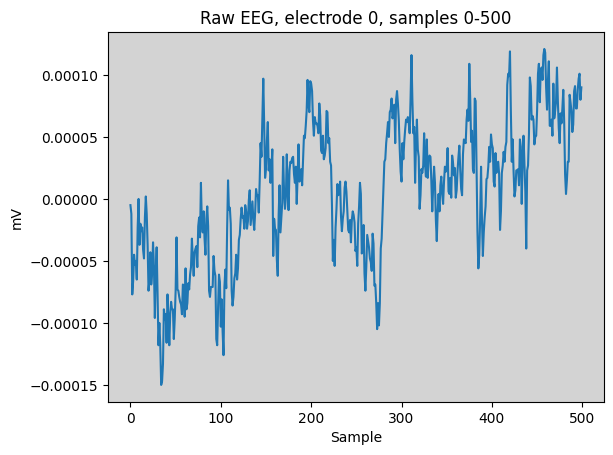

<Figure size 640x480 with 0 Axes>

In [ ]:
# Extract sample raw data for visualization (electrode 0, first 500 samples)
sample_raw_data = raw.get_data()[0, :500]  # Electrode 0, first 500 samples

plt.plot(sample_raw_data)
plt.title("Raw EEG, electrode 0, samples 0-500")
plt.ylabel("mV")
plt.xlabel("Sample")
plt.show()
plt.clf()

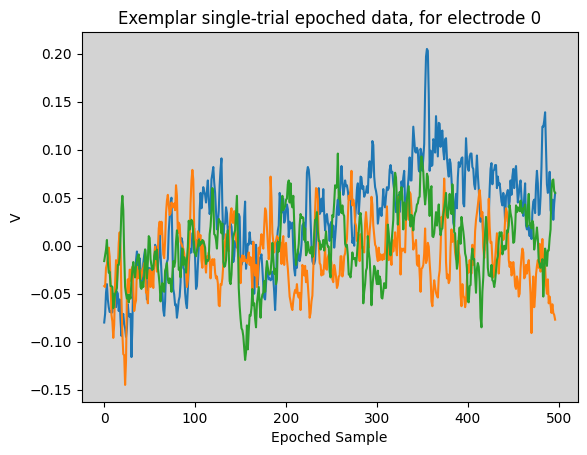

<Figure size 640x480 with 0 Axes>

In [ ]:
plt.plot(X[18:21, 0, :].T)
plt.title("Exemplar single-trial epoched data, for electrode 0")
plt.ylabel("V")
plt.xlabel("Epoched Sample")
plt.show()
plt.clf()

In [ ]:
# RAM saving
del raw, events, epoched, physionet_paths, eeg_channel_inds, parts

## **Model**

### **Utils**

In [ ]:
class AvgMeter(object):
    def __init__(self, num=40):
        self.num = num
        self.reset()

    def reset(self):
        self.losses = []

    def update(self, val):
        self.losses.append(val)

    def show(self):
        out = torch.mean(
            torch.stack(
                self.losses[np.maximum(len(self.losses)-self.num, 0):]
            )
        )
        return out

### **Wrapper**

In [ ]:
class ModelWrapper(L.LightningModule):
    def __init__(self, arch, dataset, batch_size, lr, max_epoch):
        super().__init__()

        self.arch = arch
        self.dataset = dataset
        self.batch_size = batch_size
        self.lr = lr
        self.max_epoch = max_epoch

        self.train_accuracy = Accuracy(task="binary")
        self.val_accuracy = Accuracy(task="binary")
        self.test_accuracy = Accuracy(task="binary")

        self.automatic_optimization = False

        self.train_loss = []
        self.val_loss = []

        self.train_acc = []
        self.val_acc = []

        self.train_loss_recorder = AvgMeter()
        self.val_loss_recorder = AvgMeter()

        self.train_acc_recorder = AvgMeter()
        self.val_acc_recorder = AvgMeter()

    def forward(self, x):
        return self.arch(x)

    def training_step(self, batch, batch_nb):
        x, y = batch
        y_hat = self(x)
        loss = F.binary_cross_entropy_with_logits(y_hat, y)
        self.train_accuracy.update(y_hat, y)
        acc = self.train_accuracy.compute().data.cpu()

        opt = self.optimizers()
        opt.zero_grad()
        self.manual_backward(loss)
        opt.step()

        self.train_loss_recorder.update(loss.data)
        self.train_acc_recorder.update(acc)

        self.log("train_loss", loss, prog_bar=True)
        self.log("train_acc", acc, prog_bar=True)

    def on_train_epoch_end(self):
        sch = self.lr_schedulers()
        sch.step()

        self.train_loss.append(self.train_loss_recorder.show().data.cpu().numpy())
        self.train_loss_recorder = AvgMeter()

        self.train_acc.append(self.train_acc_recorder.show().data.cpu().numpy())
        self.train_acc_recorder = AvgMeter()

    def validation_step(self, batch, batch_nb):
        x, y = batch
        y_hat = self(x)
        loss = F.binary_cross_entropy_with_logits(y_hat, y)
        self.val_accuracy.update(y_hat, y)
        acc = self.val_accuracy.compute().data.cpu()

        self.val_loss_recorder.update(loss.data)
        self.val_acc_recorder.update(acc)

        self.log("val_loss", loss, prog_bar=True)
        self.log("val_acc", acc, prog_bar=True)

    def on_validation_epoch_end(self):
        self.val_loss.append(self.val_loss_recorder.show().data.cpu().numpy())
        self.val_loss_recorder = AvgMeter()

        self.val_acc.append(self.val_acc_recorder.show().data.cpu().numpy())
        self.val_acc_recorder = AvgMeter()

    def test_step(self, batch, batch_nb):
        x, y = batch
        y_hat = self(x)
        loss = F.binary_cross_entropy_with_logits(y_hat, y)
        self.test_accuracy.update(y_hat, y)

        self.log(
            "test_loss",
            loss,
            prog_bar=True,
            logger=True,
        )
        self.log(
            "test_acc",
            self.test_accuracy.compute(),
            prog_bar=True,
            logger=True,
        )

    def on_train_end(self):

        # Loss
        loss_img_file = "/content/loss_plot.png"
        plt.plot(self.train_loss, color = 'r', label='train')
        plt.plot(self.val_loss, color = 'b', label='validation')
        plt.title("Loss Curves")
        plt.xlabel("Epoch")
        plt.ylabel("Loss")
        plt.legend()
        plt.grid()
        plt.savefig(loss_img_file)
        plt.clf()
        img = cv2.imread(loss_img_file)
        cv2_imshow(img)

        # Accuracy
        acc_img_file = "/content/acc_plot.png"
        plt.plot(self.train_acc, color = 'r', label='train')
        plt.plot(self.val_acc, color = 'b', label='validation')
        plt.title("Accuracy Curves")
        plt.xlabel("Epoch")
        plt.ylabel("Accuracy")
        plt.legend()
        plt.grid()
        plt.savefig(acc_img_file)
        plt.clf()
        img = cv2.imread(acc_img_file)
        cv2_imshow(img)

    def train_dataloader(self):
        return data.DataLoader(
            dataset=self.dataset.split("train"),
            batch_size=self.batch_size,
            shuffle=True,
        )

    def val_dataloader(self):
        return data.DataLoader(
            dataset=self.dataset.split("val"),
            batch_size=self.batch_size,
            shuffle=False,
        )

    def test_dataloader(self):
        return data.DataLoader(
            dataset=self.dataset.split("test"),
            batch_size=1,
            shuffle=False,
        )

    def configure_optimizers(self):

        optimizer = optim.Adam(
            self.parameters(),
            lr=self.lr,
        )
        lr_scheduler = {
            "scheduler": optim.lr_scheduler.MultiStepLR(
                optimizer,
                milestones=[
                    int(self.max_epoch * 0.25),
                    int(self.max_epoch * 0.5),
                    int(self.max_epoch * 0.75),
                ],
                gamma=0.1
            ),
            "name": "lr_scheduler",
        }
        return [optimizer], [lr_scheduler]

In [ ]:
print(f"Labels (y) shape: {y.shape}")


### **EEG Classification Model**

In [ ]:
import torch
from torch import nn
import torch.nn.functional as F
from mamba_ssm import Mamba


class EEGClassificationModelWithMamba(nn.Module):
    def __init__(self, eeg_channel, dropout=0.1, d_model=32, d_state=64, d_conv=4, expand=2):
        super().__init__()

        # Convolutional Feature Extractor
        self.conv = nn.Sequential(
            nn.Conv1d(
                eeg_channel, eeg_channel, 11, 1, padding=5, bias=False
            ),
            nn.BatchNorm1d(eeg_channel),
            nn.ReLU(True),
            nn.Dropout1d(dropout),
            nn.Conv1d(
                eeg_channel, eeg_channel * 2, 11, 1, padding=5, bias=False
            ),
            nn.BatchNorm1d(eeg_channel * 2),
        )

        # Mamba SSM Block
        self.mamba = Mamba(
            d_model=eeg_channel * 2,  # Input dimension from convolutional output
            d_state=d_state,         # SSM state expansion factor
            d_conv=d_conv,           # Local convolution width
            expand=expand            # Block expansion factor
        )

        # MLP for Classification
        self.mlp = nn.Sequential(
            nn.Linear(eeg_channel * 2, eeg_channel // 2),
            nn.ReLU(True),
            nn.Dropout(dropout),
            nn.Linear(eeg_channel // 2, 1),  # Binary classification
        )

    def forward(self, x):
        # Input Shape: (batch, channels, time)
        x = self.conv(x)  # Shape: (batch, conv_channels, time)
        x = x.permute(0, 2, 1)  # Shape: (batch, time, conv_channels) for Mamba
        x = self.mamba(x)       # Shape: (batch, time, conv_channels)
        x = x.mean(dim=1)       # Shape: (batch, conv_channels), global pooling
        x = self.mlp(x)         # Shape: (batch, 1), binary classification
        return x


# Instantiate the model
eeg_channel = 64  # Adjust this to match the number of EEG channels in your data
dropout = 0.125
model = EEGClassificationModelWithMamba(eeg_channel=eeg_channel, dropout=dropout).to("cuda")

# Example Input
batch_size = 2
time_steps = 497  # Example time dimension
x = torch.randn(batch_size, eeg_channel, time_steps).to("cuda")  # Shape: (batch, channels, time)

# Forward Pass
out = model(x)
print(f"Output Shape: {out.shape}")  # Expected: (batch, 1)


Output Shape: torch.Size([2, 1])


In [ ]:
MODEL_NAME = "EEGClassificationModelWithMamba"
model = EEGClassificationModelWithMamba(eeg_channel=EEG_CHANNEL, dropout=0.125)

## **Training**

In [ ]:
MAX_EPOCH = 100
BATCH_SIZE = 10
LR = 5e-4
CHECKPOINT_DIR = os.getcwd()
SEED = int(np.random.randint(2147483647))

print(f"Random seed: {SEED}")

model = ModelWrapper(model, eeg_dataset, BATCH_SIZE, LR, MAX_EPOCH)

!rm -rf logs/

Random seed: 1651152350


In [ ]:
print(f"Labels (y) shape: {y.shape}")


In [ ]:
%reload_ext tensorboard
%tensorboard --logdir=logs/lightning_logs/

INFO: Seed set to 1651152350
INFO:lightning.fabric.utilities.seed:Seed set to 1651152350
INFO: GPU available: True (cuda), used: True
INFO:lightning.pytorch.utilities.rank_zero:GPU available: True (cuda), used: True
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: HPU available: False, using: 0 HPUs
INFO:lightning.pytorch.utilities.rank_zero:HPU available: False, using: 0 HPUs
/usr/local/lib/python3.10/dist-packages/lightning/pytorch/callbacks/model_checkpoint.py:654: Checkpoint directory /content/drive/MyDrive/capstone exists and is not empty.
INFO: LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:lightning.pytorch.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO: 
  | Name           | Type                            | Params | Mode 
---------------------------------------------------------------------------
0 | arch           | EEGClassificationModelWithMamba | 293 K  | train
1 | tra

INFO: `Trainer.fit` stopped: `max_epochs=100` reached.
INFO:lightning.pytorch.utilities.rank_zero:`Trainer.fit` stopped: `max_epochs=100` reached.


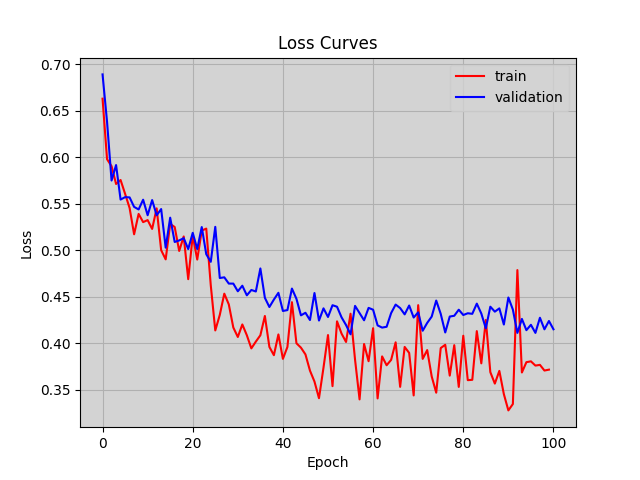

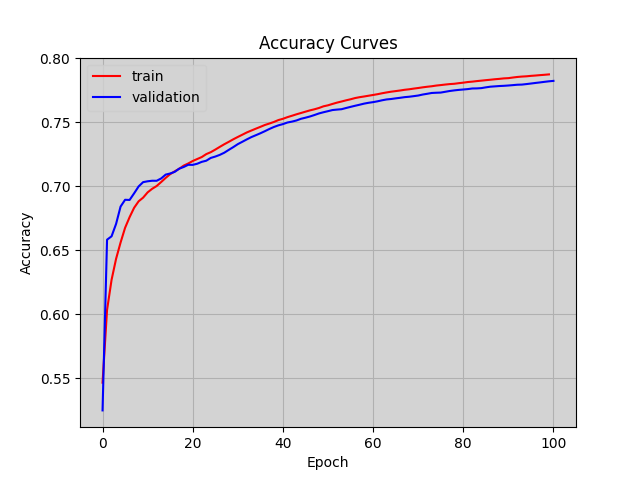

In [ ]:
tensorboardlogger = TensorBoardLogger(save_dir="logs/")
csvlogger = CSVLogger(save_dir="logs/")
lr_monitor = LearningRateMonitor(logging_interval='step')
checkpoint = ModelCheckpoint(
    monitor='val_acc',
    dirpath=CHECKPOINT_DIR,
    mode='max',
)
early_stopping = EarlyStopping(
    monitor="val_acc", min_delta=0.00, patience=3, verbose=False, mode="max"
)


seed_everything(SEED, workers=True)


trainer = Trainer(
    accelerator="auto",
    devices=1,
    max_epochs=MAX_EPOCH,
    logger=[tensorboardlogger, csvlogger],
    callbacks=[lr_monitor, checkpoint, early_stopping],
    log_every_n_steps=5,
)
trainer.fit(model)

In [ ]:
print(f"Labels (y) shape: {y.shape}")


## **Testing**

In [ ]:
trainer.test(ckpt_path="best")

os.rename(
    checkpoint.best_model_path,
    os.path.join(CHECKPOINT_DIR, f"{MODEL_NAME}_best.ckpt")
)

INFO: Restoring states from the checkpoint path at /content/drive/MyDrive/capstone/epoch=99-step=27400.ckpt
INFO:lightning.pytorch.utilities.rank_zero:Restoring states from the checkpoint path at /content/drive/MyDrive/capstone/epoch=99-step=27400.ckpt
INFO: LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:lightning.pytorch.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO: Loaded model weights from the checkpoint at /content/drive/MyDrive/capstone/epoch=99-step=27400.ckpt
INFO:lightning.pytorch.utilities.rank_zero:Loaded model weights from the checkpoint at /content/drive/MyDrive/capstone/epoch=99-step=27400.ckpt


Testing: |          | 0/? [00:00<?, ?it/s]

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃        Test metric        ┃       DataLoader 0        ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│         test_acc          │     0.70924973487854      │
│         test_loss         │     0.820400595664978     │
└───────────────────────────┴───────────────────────────┘

In [ ]:
print(f"Labels (y) shape: {y.shape}")


## **Inference**

In [ ]:
for _ in range(5):
    N_SAMPLE = X.shape[0]
    sample_idx = random.randint(0, N_SAMPLE - 1)
    sample = X[sample_idx]

    trainer = Trainer()
    prediction = trainer.predict(
        model=model,
        dataloaders=data.DataLoader(
            dataset=EEGDataset.inference_dataset(X[sample_idx]),
            batch_size=1,
            shuffle=False,
        ),
        ckpt_path=os.path.join(CHECKPOINT_DIR, f"{MODEL_NAME}_best.ckpt"),
    )[0]

    PREDICTED = CLASSES[int(torch.sigmoid(prediction) > 0.5)]
    ACTUAL = CLASSES[y[sample_idx]]
    print("\n\n\n")
    print(f"Imagining {PREDICTED} hand movement!")
    print(f"Ground-truth: {ACTUAL}!")

    plt.plot(sample.T)
    plt.title(
        f"Exemplar of epoched data, for electrode 0-63\nActual Label : {ACTUAL}\nPredicted Label : {PREDICTED}"
    )
    plt.ylabel("V")
    plt.xlabel("Epoched Sample")
    plt.show()
    plt.clf()

    print("\n\n\n")


INFO: GPU available: True (cuda), used: True
INFO:lightning.pytorch.utilities.rank_zero:GPU available: True (cuda), used: True
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: HPU available: False, using: 0 HPUs
INFO:lightning.pytorch.utilities.rank_zero:HPU available: False, using: 0 HPUs
INFO: Restoring states from the checkpoint path at /content/drive/MyDrive/capstone/EEGClassificationModelWithMamba_best.ckpt
INFO:lightning.pytorch.utilities.rank_zero:Restoring states from the checkpoint path at /content/drive/MyDrive/capstone/EEGClassificationModelWithMamba_best.ckpt
INFO: LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:lightning.pytorch.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO: Loaded model weights from the checkpoint at /content/drive/MyDrive/capstone/EEGClassificationModelWithMamba_best.ckpt
INFO:lightning.pytorch.utilities.rank_zero:Loaded model weights from the checkp

Predicting: |          | 0/? [00:00<?, ?it/s]